In [12]:
# STEP 1 — IMPORT LIBRARY
import os
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
 

In [13]:
# STEP 2 — KONFIGURASI
BASE_DIR = '/Users/admin/Documents/Tugas Semester 7/Matkul Analisis Big Data/Praktikum Klasifikasi Citra/flowers'
IMG_SIZE = (160, 160)     # lebih kecil = lebih cepat
BATCH = 32
EPOCHS = 8                # fase 1: latih "kepala" klasifikasi
FINE_TUNE_EPOCHS = 3      # fase 2: fine-tune sebentar
SEED = 42
OUT_DIR = 'output'
os.makedirs(OUT_DIR, exist_ok=True)
 
tf.keras.utils.set_random_seed(SEED)
 
 
def resolve_data_dir(path):
    """Kalau folder kelas ada di dalam folder bersarang (mis. flowers/flowers), masuk otomatis."""
    while True:
        subs = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
        if len(subs) == 1:
            path = os.path.join(path, subs[0])
        else:
            return path
 
DATA_DIR = resolve_data_dir(BASE_DIR)
print(f' Dataset: {DATA_DIR}')

 Dataset: /Users/admin/Documents/Tugas Semester 7/Matkul Analisis Big Data/Praktikum Klasifikasi Citra/flowers


In [14]:
common = dict(
    validation_split=0.2,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH,
    label_mode='categorical',
)
train_raw = tf.keras.utils.image_dataset_from_directory(DATA_DIR, subset='training', **common)
val_raw = tf.keras.utils.image_dataset_from_directory(DATA_DIR, subset='validation', **common)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
print(f'Kelas: ({NUM_CLASSES} {class_names}')

with open(os.path.join(OUT_DIR, 'class_names.json'), 'w') as f:
    json.dump(class_names, f)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_raw.cache().prefetch(buffer_size=AUTOTUNE)

Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Kelas: (5 ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


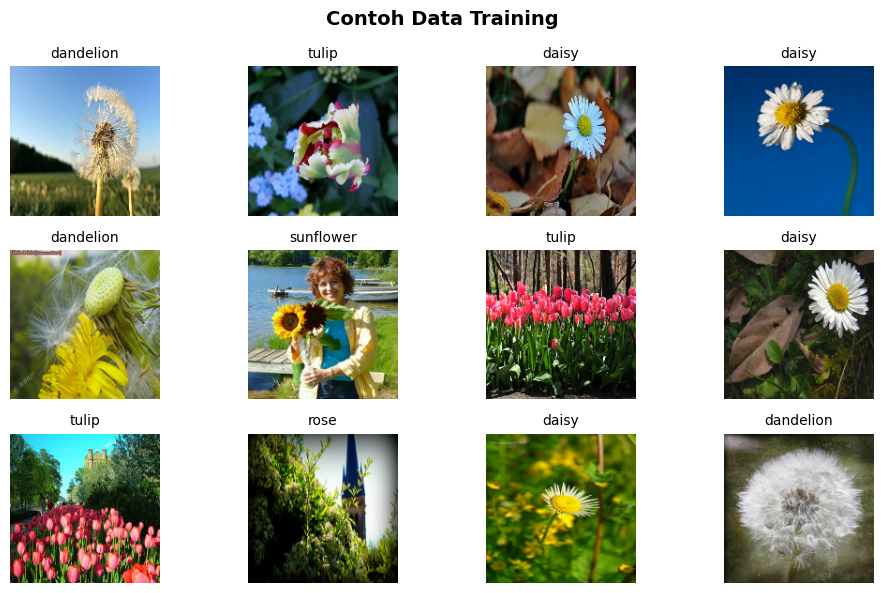

In [15]:
plt.figure(figsize=(10, 6))
for images, labels in train_raw.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[int(np.argmax(labels[i]))], fontsize=10)
        plt.axis('off')

plt.suptitle('Contoh Data Training', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '1_sample_data.png'), dpi=120)

In [16]:
import os, ssl, certifi

os.environ['SSL_CERT_FILE'] = certifi.where()
os.environ['REQUESTS_CA_BUNDLE'] = certifi.where()
ssl._create_default_https_context = lambda *args, **kwargs: ssl.create_default_context(cafile=certifi.where())

augment = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
], name='augmentation')

# --- Base model pretrained ---
try:
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet'
    )
except Exception as e:
    raise RuntimeError(
        "Gagal mengunduh bobot ImageNet. Cek koneksi internet, atau unduh manual "
        "dengan curl (lihat penjelasan sebelumnya), lalu pakai weights=None + load_weights()."
    ) from e

base_model.trainable = False

# --- Susun model ---
inputs = layers.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = layers.Rescaling(1. / 127.5, offset=-1)(x)  # skala [-1, 1] sesuai MobileNetV2
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
model = models.Model(inputs, outputs, name ='mobilenetv2')
model.compile(
    optimizer=Adam(1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
    )
model.summary()

Model: "mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
ckpt_path = os.path.join(OUT_DIR, 'flower_cnn.keras')
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
    ModelCheckpoint(ckpt_path, monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=1, min_lr=1e-6),
]

t0 = time.time()
print('\nFase 1: latih classifier head...')
h1 = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds, callbacks=callbacks)

print('\nFase 2: fine-tune 30 layer terakhir...')
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
h2 = model.fit(train_ds, epochs=FINE_TUNE_EPOCHS, validation_data=val_ds, callbacks=callbacks)

print(f'\nTotal waktu training: {(time.time() - t0) / 60:.1f} menit')

# Gabungkan history kedua fase
history = {k: h1.history[k] + h2.history[k] for k in h1.history}


Fase 1: latih classifier head...
Epoch 1/8


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


108/108 ━━━━━━━━━━━━━━━━━━━━ 37s 302ms/step - accuracy: 0.6343 - loss: 0.9620 - val_accuracy: 0.8482 - val_loss: 0.4877 - learning_rate: 0.0010
Epoch 2/8
108/108 ━━━━━━━━━━━━━━━━━━━━ 33s 304ms/step - accuracy: 0.8098 - loss: 0.5163 - val_accuracy: 0.8667 - val_loss: 0.4177 - learning_rate: 0.0010
Epoch 3/8
108/108 ━━━━━━━━━━━━━━━━━━━━ 34s 313ms/step - accuracy: 0.8393 - loss: 0.4444 - val_accuracy: 0.8818 - val_loss: 0.3701 - learning_rate: 0.0010
Epoch 4/8
108/108 ━━━━━━━━━━━━━━━━━━━━ 33s 311ms/step - accuracy: 0.8547 - loss: 0.4053 - val_accuracy: 0.8853 - val_loss: 0.3533 - learning_rate: 0.0010
Epoch 5/8
108/108 ━━━━━━━━━━━━━━━━━━━━ 34s 315ms/step - accuracy: 0.8599 - loss: 0.3806 - val_accuracy: 0.8864 - val_loss: 0.3509 - learning_rate: 0.0010
Epoch 6/8
108/108 ━━━━━━━━━━━━━━━━━━━━ 31s 291ms/step - accuracy: 0.8628 - loss: 0.3777 - val_accuracy: 0.8876 - val_loss: 0.3454 - learning_rate: 0.0010
Epoch 7/8
108/108 ━━━━━━━━━━━━━━━━━━━━ 31s 288ms/step - accuracy: 0.8807 - loss: 0.337


Akurasi Validasi Akhir (acc = 89.80%)
Loss Validasi (0.3204)


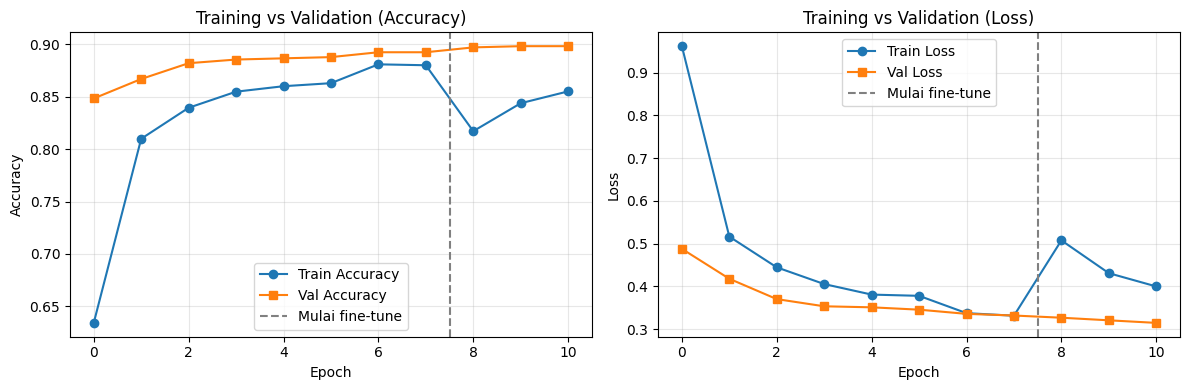


Jumlah data validasi: 863
Kelas aktual ditemukan: [0 1 2 3 4]
Kelas prediksi ditemukan: [0 1 2 3 4]

CLASSIFICATION REPORT

              precision    recall  f1-score   support

       daisy      0.854     0.896     0.875       144
   dandelion      0.912     0.908     0.910       206
        rose      0.842     0.854     0.848       137
   sunflower      0.935     0.913     0.924       172
       tulip      0.925     0.907     0.916       204

    accuracy                          0.898       863
   macro avg      0.894     0.895     0.894       863
weighted avg      0.899     0.898     0.898       863



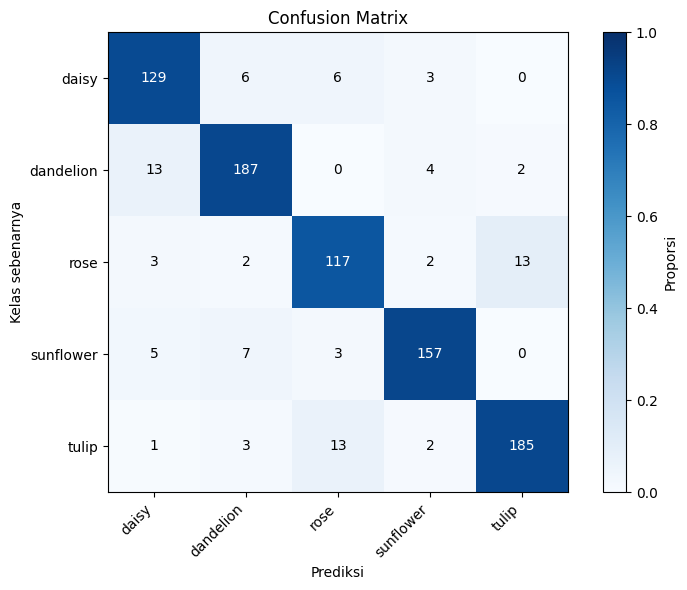

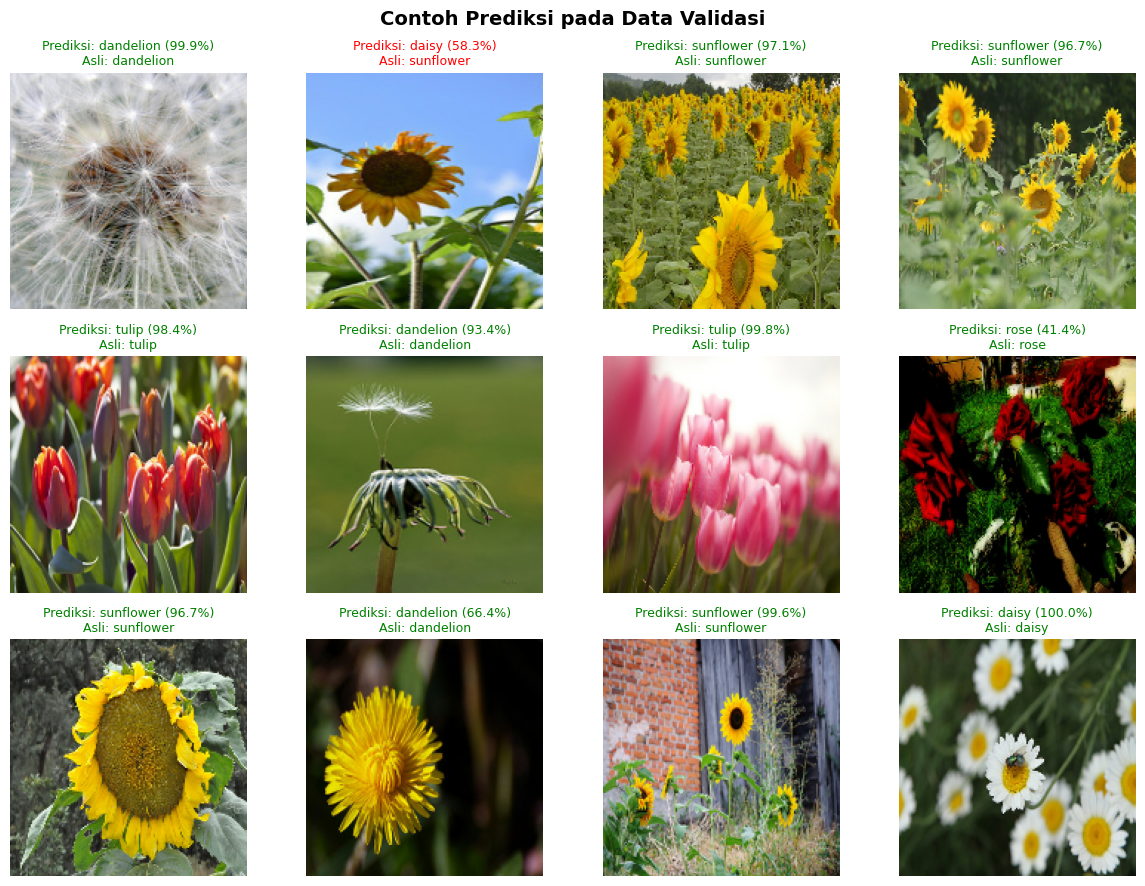


Semua evaluasi selesai.
Hasil disimpan di: /Users/admin/Documents/Tugas Semester 7/Matkul Analisis Big Data/Praktikum Klasifikasi Citra/output
- 2_training_curves.png
- 3_confusion_matrix.png
- 4_sample_predictions.png


In [18]:
# EVALUASI MODEL AUGMENTED

import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Pastikan folder output tersedia
os.makedirs(OUT_DIR, exist_ok=True)

# 1. Evaluasi akhir
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"\nAkurasi Validasi Akhir (acc = {acc * 100:.2f}%)")
print(f"Loss Validasi ({loss:.4f})")

# 2. Grafik akurasi dan loss
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Gunakan history model untuk melihat jejak training
split = len(h1.history['accuracy'])

for a, (metric, title) in zip(ax, [('accuracy', 'Accuracy'), ('loss', 'Loss')]):
    a.plot(history[metric], "o-", label=f"Train {title}")
    a.plot(history[f"val_{metric}"], "s-", label=f"Val {title}")

    if 0 < split < len(history[metric]):
        a.axvline(
            split - 0.5,
            color="gray",
            linestyle="--",
            label="Mulai fine-tune",
        )

    a.set_title(f'Training vs Validation ({title})')
    a.set_xlabel('Epoch')
    a.set_ylabel(title)
    a.legend()
    a.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "2_training_curves.png"),
    dpi=120,
    bbox_inches="tight",
)
plt.show()

# 3. Menghasilkan label prediksi dan contoh gambar
y_true, y_pred = [], []
imgs_keep, probs_keep = [], []

for xb, yb in val_ds:
    # Prediksi satu batch
    p = model.predict(xb, verbose=0)

    # Label aktual, mendukung one-hot maupun label integer
    yb_np = yb.numpy()
    if yb_np.ndim > 1 and yb_np.shape[-1] > 1:
        true_batch = np.argmax(yb_np, axis=1)
    else:
        true_batch = yb_np.reshape(-1).astype(int)

    pred_batch = np.argmax(p, axis=1)

    y_true.extend(true_batch)
    y_pred.extend(pred_batch)

    # Simpan maksimal 16 gambar untuk visualisasi
    n_keep = min(16 - len(imgs_keep), len(xb))
    if n_keep > 0:
        imgs_keep.extend(xb[:n_keep].numpy())
        probs_keep.extend(p[:n_keep])

y_true = np.asarray(y_true, dtype=int)
y_pred = np.asarray(y_pred, dtype=int)
probs_keep = np.asarray(probs_keep)

# Set label kelas model
labels = list(range(NUM_CLASSES))

# Pastikan nama kelas cocok dengan output model
assert len(class_names) == NUM_CLASSES, (
    f"Jumlah class_names ({len(class_names)}) "
    f"tidak sama dengan NUM_CLASSES ({NUM_CLASSES})."
)

print("\nJumlah data validasi:", len(y_true))
print("Kelas aktual ditemukan:", np.unique(y_true))
print("Kelas prediksi ditemukan:", np.unique(y_pred))

# 4. Classification report
print("\nCLASSIFICATION REPORT\n")
print(
    classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=class_names,
        digits=3,
        zero_division=0,
    )
)

# 5. Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)

# Normalisasi berdasarkan jumlah data aktual setiap kelas
row_sum = cm.sum(axis=1, keepdims=True)

cm_pct = np.divide(
    cm,
    row_sum,
    out=np.zeros_like(cm, dtype=float),
    where=row_sum != 0,
)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Proporsi")

ax.set_xticks(labels)
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(labels)
ax.set_yticklabels(class_names)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm_pct[i, j] > 0.5 else "black",
        )

ax.set_xlabel("Prediksi")
ax.set_ylabel("Kelas sebenarnya")
ax.set_title("Confusion Matrix")

plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "3_confusion_matrix.png"),
    dpi=120,
    bbox_inches="tight",
)
plt.show()

# 6. Contoh prediksi gambar
n_show = min(12, len(imgs_keep))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for i, a in enumerate(axes):
    if i >= n_show:
        a.axis("off")
        continue

    # Gambar dari dataset biasanya sudah dinormalisasi
    img = imgs_keep[i].copy()

    # Ubah skala (-1, 1) atau [0, 1] agar dapat ditampilkan
    if img.min() < 0:
        img = (img + 1.0) / 2.0
    elif img.max() > 1:
        img = img / 255.0

    img = np.clip(img, 0, 1)

    pred = int(np.argmax(probs_keep[i]))
    true = int(y_true[i])
    conf = probs_keep[i][pred] * 100

    a.imshow(img)
    a.set_title(
        f"Prediksi: {class_names[pred]} ({conf:.1f}%)\n"
        f"Asli: {class_names[true]}",
        color="green" if pred == true else "red",
        fontsize=9,
    )
    a.axis("off")

plt.suptitle(
    "Contoh Prediksi pada Data Validasi",
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "4_sample_predictions.png"),
    dpi=120,
    bbox_inches="tight",
)
plt.show()

# 7. Selesai
print("\nSemua evaluasi selesai.")
print("Hasil disimpan di:", os.path.abspath(OUT_DIR))
print("- 2_training_curves.png")
print("- 3_confusion_matrix.png")
print("- 4_sample_predictions.png")

In [19]:
model.save(os.path.join(OUT_DIR, 'final_flower_cnn_model.keras'))
loaded = tf.keras.models.load_model(os.path.join(OUT_DIR, 'final_flower_cnn_model.keras'))
print(f'\n Model tersimpan di folder "{OUT_DIR}" dan berhasil di-load ulang.')
 
plt.show()
 
# Jalankan aplikasi:
#   cd D:\Analitik_Data\Flowers_Recognition
#   streamlit run app.py
 


 Model tersimpan di folder "output" dan berhasil di-load ulang.
